# 02 - Exploratory Data Analysis (EDA)
## NASA C-MAPSS Turbofan Degradation (FD001 Training Trajectories)

### Objective & ML Guidelines
1. Perform an in-depth exploratory analysis strictly on the **training data** (`train_FD001.txt`).
2. Adhere to ML best practices: **Zero data leakage** (test data remains untouched).
3. Investigate sensor variances to detect non-informative or flat sensor channels.
4. Analyze telemetry distributions, correlations, and multi-collinearity.
5. Inspect individual engine degradation trajectories without mixing unit records.
6. Synthesize findings into candidate feature sets and preliminary technical observations.

*Note: No features are removed yet, and no ML models are trained.*

In [1]:
import sys
from pathlib import Path

# Setup project root
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_train_data

# Styling and plot config
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.autolayout'] = False

RANDOM_STATE = 42
FIGURES_DIR = project_root / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load training data
train_df = load_train_data(data_dir=project_root / "data" / "raw")
print(f"Loaded Training Data: {train_df.shape[0]:,} rows across {train_df.shape[1]} columns.")

Loaded Training Data: 20,631 rows across 26 columns.


---
## 1. Dataset Dimensions, Engines, and Lifetime Analysis

Each engine unit begins at normal operating condition and degrades until system failure. Let us inspect the distribution of total operational cycles per engine.

In [2]:
SENSOR_COLS = [f'sensor_{i}' for i in range(1, 22)]
SETTING_COLS = ['operational_setting_1', 'operational_setting_2', 'operational_setting_3']

cycles_per_unit = train_df.groupby('unit_number')['time_cycles'].max()

print("=" * 60)
print("                   ENGINE LIFETIME METRICS")
print("=" * 60)
print(f"Total Operational Engines : {train_df['unit_number'].nunique()}")
print(f"Minimum Lifetime          : {cycles_per_unit.min()} cycles (Engine #{cycles_per_unit.idxmin()})")
print(f"Maximum Lifetime          : {cycles_per_unit.max()} cycles (Engine #{cycles_per_unit.idxmax()})")
print(f"Mean Lifetime             : {cycles_per_unit.mean():.2f} cycles")
print(f"Median Lifetime           : {cycles_per_unit.median():.1f} cycles")
print(f"Standard Deviation        : {cycles_per_unit.std():.2f} cycles")

                   ENGINE LIFETIME METRICS
Total Operational Engines : 100
Minimum Lifetime          : 128 cycles (Engine #39)
Maximum Lifetime          : 362 cycles (Engine #69)
Mean Lifetime             : 206.31 cycles
Median Lifetime           : 199.0 cycles
Standard Deviation        : 46.34 cycles


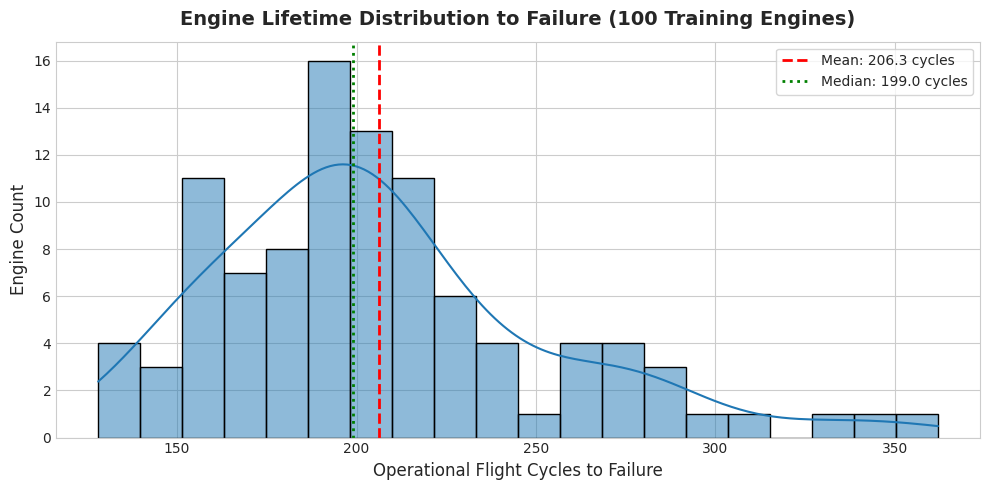

In [3]:
# Plot: Engine Lifetime Distribution
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(cycles_per_unit, kde=True, bins=20, color='#1f77b4', ax=ax, edgecolor='black')
ax.axvline(cycles_per_unit.mean(), color='red', linestyle='--', linewidth=2, label=f'Mean: {cycles_per_unit.mean():.1f} cycles')
ax.axvline(cycles_per_unit.median(), color='green', linestyle=':', linewidth=2, label=f'Median: {cycles_per_unit.median():.1f} cycles')
ax.set_title('Engine Lifetime Distribution to Failure (100 Training Engines)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Operational Flight Cycles to Failure', fontsize=12)
ax.set_ylabel('Engine Count', fontsize=12)
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '05_engine_lifetime_distribution.png', dpi=300)
plt.show()

---
## 2. Sensor Variance & Near-Zero Variance Detection

Sensors with constant values across all operating cycles offer zero predictive information for regression modeling. We calculate variance and standard deviation for all 21 sensors using a threshold $\sigma^2 < 10^{-5}$.

In [4]:
variances = train_df[SENSOR_COLS].var()
stds = train_df[SENSOR_COLS].std()

variance_df = pd.DataFrame({
    'Sensor': SENSOR_COLS,
    'Variance': variances,
    'StdDev': stds
}).reset_index(drop=True)

ZERO_VAR_THRESHOLD = 1e-5
flat_sensors = variance_df[variance_df['Variance'] < ZERO_VAR_THRESHOLD]['Sensor'].tolist()
active_sensors = variance_df[variance_df['Variance'] >= ZERO_VAR_THRESHOLD]['Sensor'].tolist()

print(f"Total Sensors Evaluated       : {len(SENSOR_COLS)}")
print(f"Near-Zero Variance Sensors ({len(flat_sensors)}): {flat_sensors}")
print(f"Informative Active Sensors ({len(active_sensors)}): {active_sensors}")
print("\nDetailed Sensor Variance Table:")
variance_df

Total Sensors Evaluated       : 21
Near-Zero Variance Sensors (7): ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Informative Active Sensors (14): ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

Detailed Sensor Variance Table:


,Sensor,Variance,StdDev
0,sensor_1,0.000000e+00,0.000000e+00
1,sensor_2,2.500533e-01,5.000533e-01
2,sensor_3,3.759099e+01,6.131150e+00
3,sensor_4,8.101089e+01,9.000605e+00
4,sensor_5,2.840037e-29,5.329200e-15
5,sensor_6,1.929279e-06,1.388985e-03
6,sensor_7,7.833883e-01,8.850923e-01
7,sensor_8,5.038938e-03,7.098548e-02
8,sensor_9,4.876536e+02,2.208288e+01
9,sensor_10,0.000000e+00,0.000000e+00


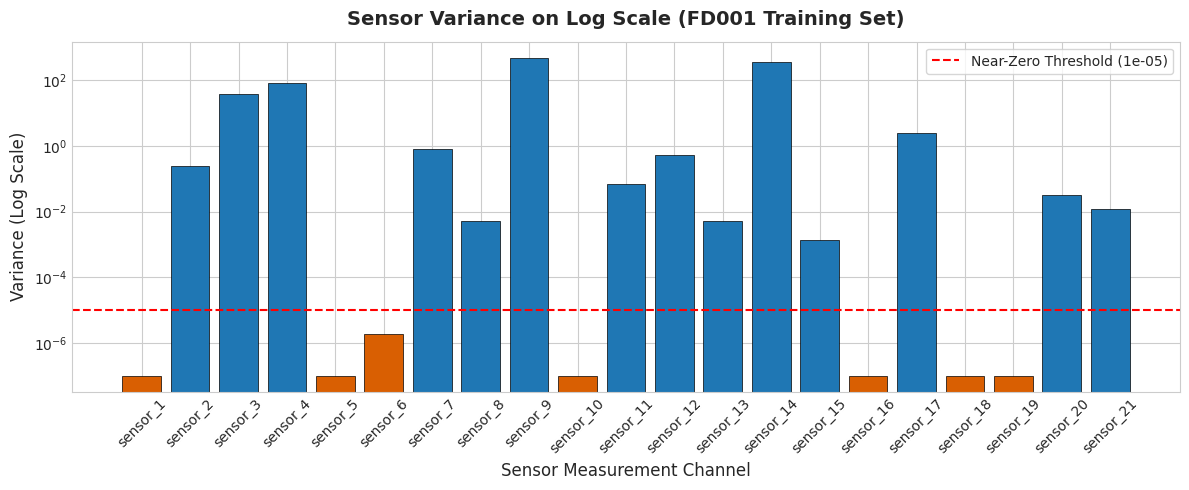

In [5]:
# Plot: Sensor Variance Bar Chart
fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#d95f02' if s in flat_sensors else '#1f77b4' for s in variance_df['Sensor']]

ax.bar(variance_df['Sensor'], np.maximum(variance_df['Variance'], 1e-7), color=colors, edgecolor='black', linewidth=0.5)
ax.axhline(ZERO_VAR_THRESHOLD, color='red', linestyle='--', linewidth=1.5, 
           label=f'Near-Zero Threshold ({ZERO_VAR_THRESHOLD})')
ax.set_yscale('log')
ax.set_title('Sensor Variance on Log Scale (FD001 Training Set)', fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Variance (Log Scale)', fontsize=12)
ax.set_xlabel('Sensor Measurement Channel', fontsize=12)
ax.tick_params(axis='x', rotation=45)
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '01_sensor_variance.png', dpi=300)
plt.show()

---
## 3. Sensor Distributions (Informative Subsets)

We analyze the distributions and value ranges of the active sensor channels. To compare all sensors uniformly on a single visualization, we normalize their ranges to $[0, 1]$ using min-max scaling.

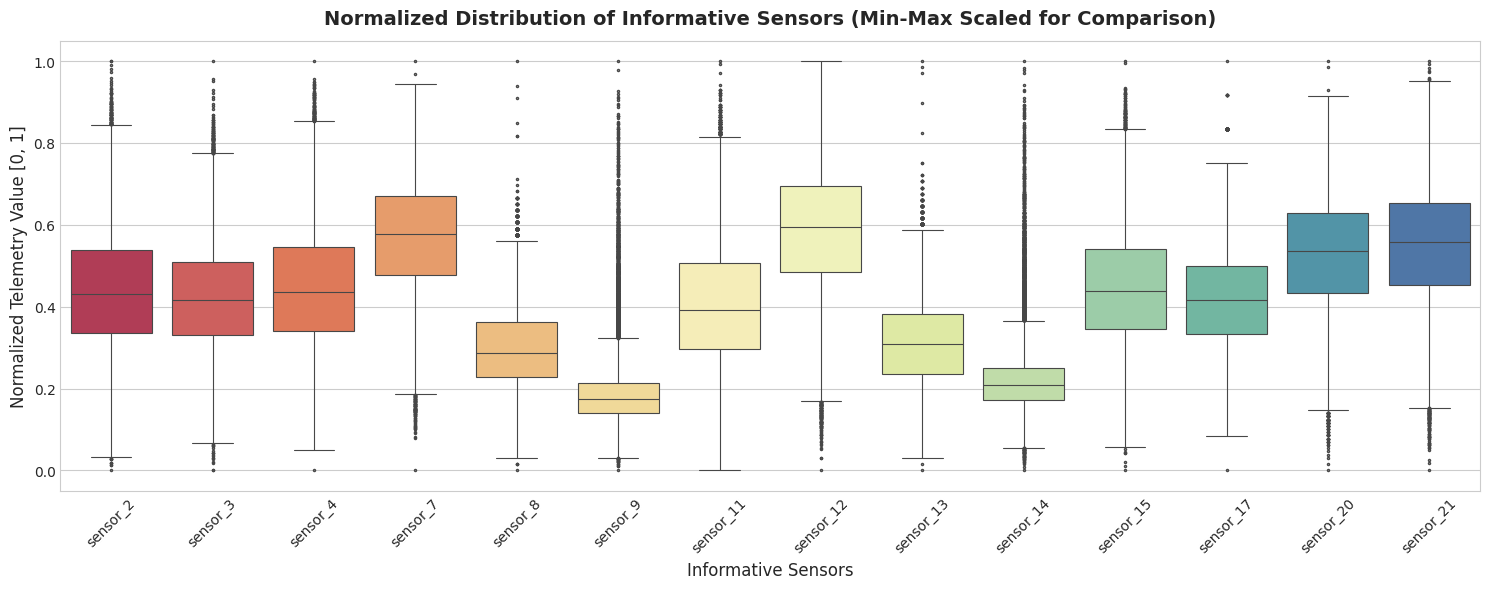

In [6]:
df_norm = (train_df[active_sensors] - train_df[active_sensors].min()) / (train_df[active_sensors].max() - train_df[active_sensors].min())

fig, ax = plt.subplots(figsize=(15, 6))
sns.boxplot(data=df_norm, ax=ax, palette='Spectral', fliersize=1.5, linewidth=0.8)
ax.set_title('Normalized Distribution of Informative Sensors (Min-Max Scaled for Comparison)', fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Normalized Telemetry Value [0, 1]', fontsize=12)
ax.set_xlabel('Informative Sensors', fontsize=12)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '02_sensor_distributions.png', dpi=300)
plt.show()

---
## 4. Correlation Analysis Between Informative Sensors

Understanding correlations helps detect multicollinearity among sensors measuring coupled physical processes (e.g., temperatures, rotor speeds, and pressures).

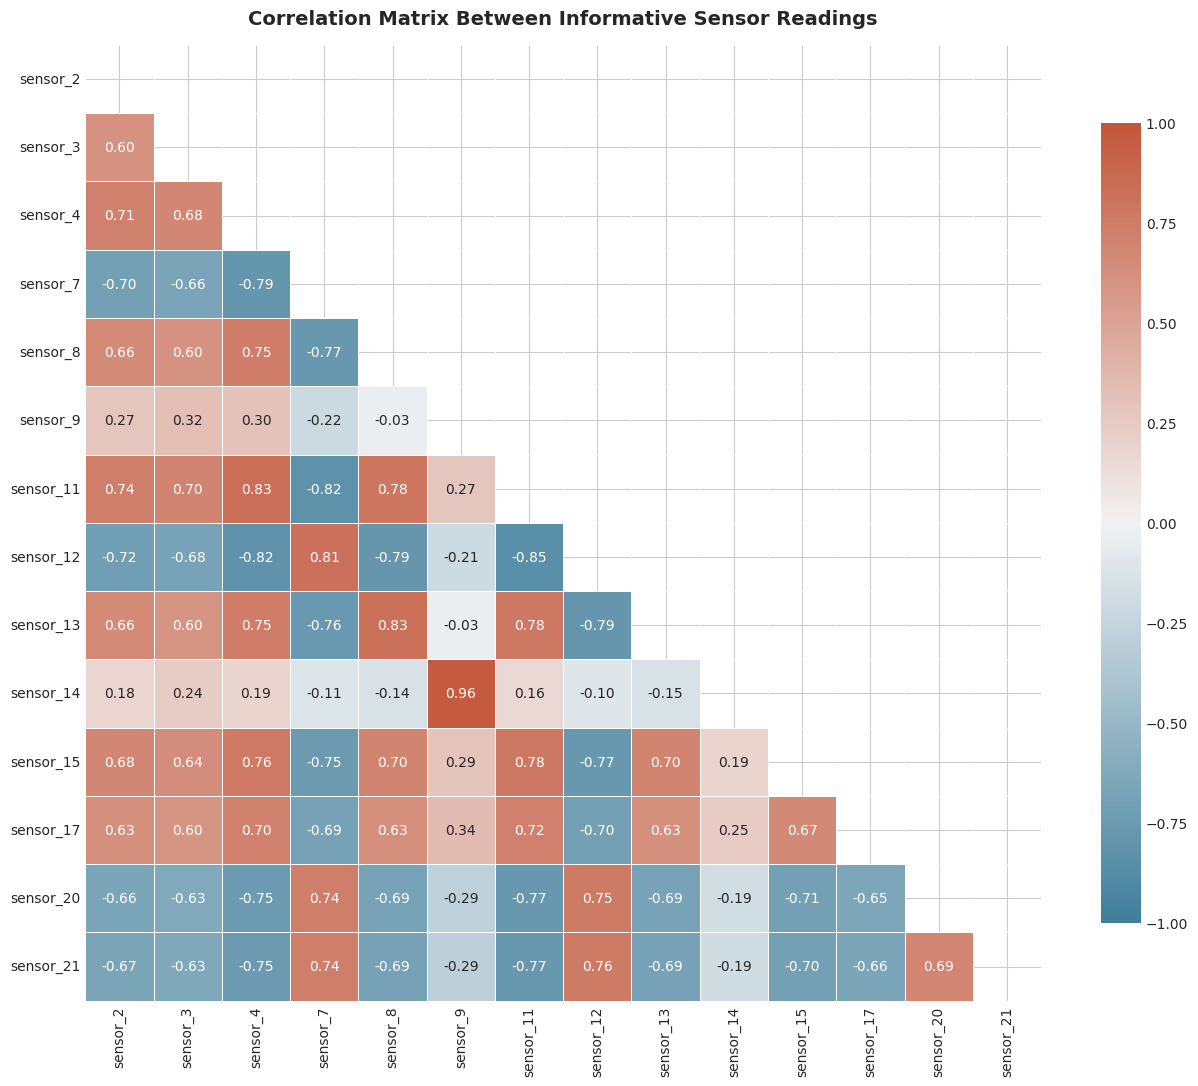

In [7]:
plt.figure(figsize=(13, 11))
corr = train_df[active_sensors].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(corr, mask=mask, cmap=cmap, vmax=1.0, vmin=-1.0, center=0,
            annot=True, fmt='.2f', square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix Between Informative Sensor Readings', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '03_sensor_correlation_heatmap.png', dpi=300)
plt.show()

---
## 5. Operational Settings Distribution

In dataset FD001, the simulation was conducted at a single sea-level operating regime. Let us inspect `operational_setting_1`, `operational_setting_2`, and `operational_setting_3`.

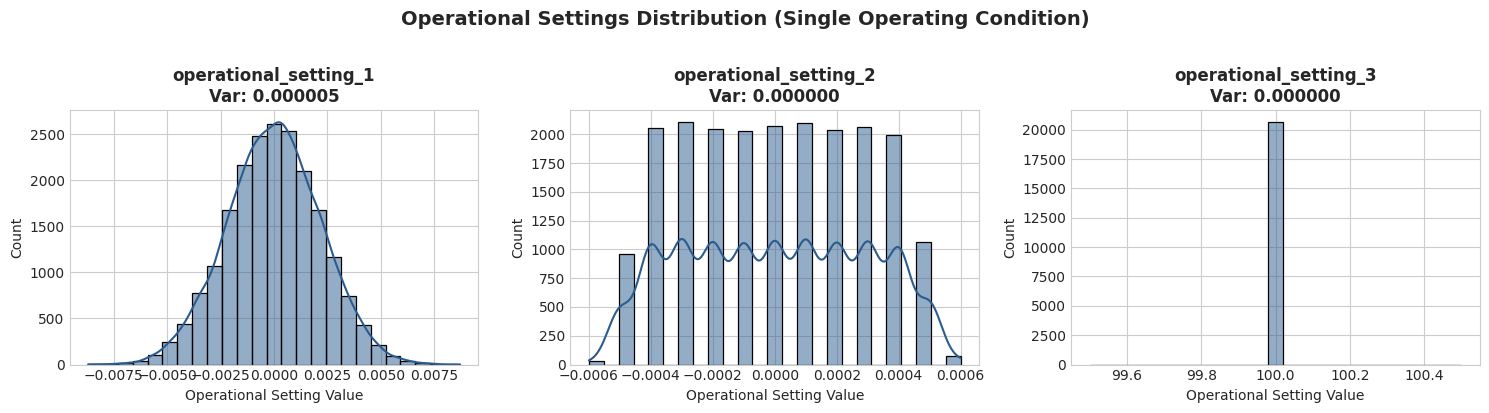

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, setting in enumerate(SETTING_COLS):
    sns.histplot(train_df[setting], ax=axes[i], kde=True, color='#2b5c8f', bins=25)
    axes[i].set_title(f'{setting}\nVar: {train_df[setting].var():.6f}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Operational Setting Value')
plt.suptitle('Operational Settings Distribution (Single Operating Condition)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_operational_settings_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

---
## 6. Sensor Degradation Trajectories Over Engine Lifetimes

**Critical ML Visualization Rule**: We group strictly by `unit_number`. Individual engine trajectories must never be combined or averaged across unaligned time axes, which would obscure distinct engine-level degradation trends.

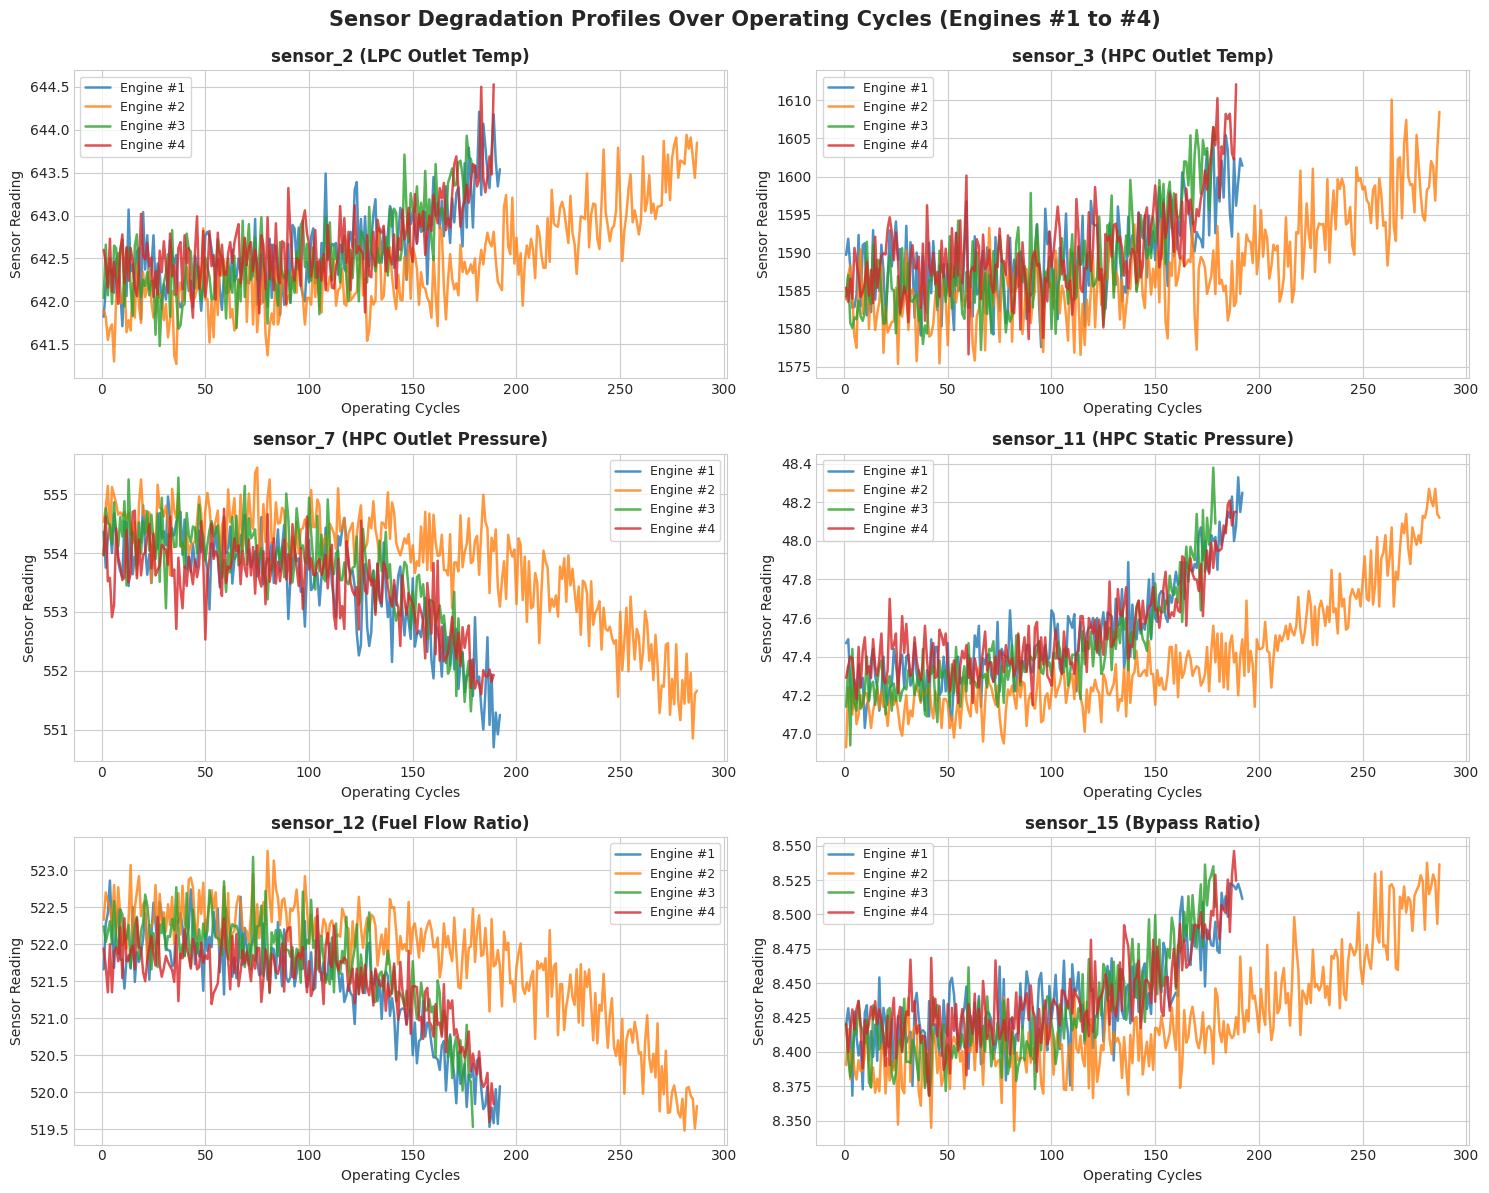

In [9]:
sample_engines = [1, 2, 3, 4]
key_sensors = [
    ('sensor_2', 'sensor_2 (LPC Outlet Temp)'),
    ('sensor_3', 'sensor_3 (HPC Outlet Temp)'),
    ('sensor_7', 'sensor_7 (HPC Outlet Pressure)'),
    ('sensor_11', 'sensor_11 (HPC Static Pressure)'),
    ('sensor_12', 'sensor_12 (Fuel Flow Ratio)'),
    ('sensor_15', 'sensor_15 (Bypass Ratio)')
]

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for ax, (s_col, s_name) in zip(axes.flatten(), key_sensors):
    for unit, color in zip(sample_engines, palette):
        engine_subset = train_df[train_df['unit_number'] == unit]
        ax.plot(engine_subset['time_cycles'], engine_subset[s_col], 
                label=f'Engine #{unit}', color=color, alpha=0.8, lw=1.8)
    ax.set_title(s_name, fontsize=12, fontweight='bold')
    ax.set_xlabel('Operating Cycles', fontsize=10)
    ax.set_ylabel('Sensor Reading', fontsize=10)
    ax.legend(loc='best', frameon=True, fontsize=9)

plt.suptitle('Sensor Degradation Profiles Over Operating Cycles (Engines #1 to #4)', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '06_sensor_degradation_trajectories.png', dpi=300)
plt.show()

---
## 7. Preliminary EDA Report

### `USEFUL_FEATURE_CANDIDATES`
The following 14 sensors exhibit pronounced, monotonic degradation profiles with physical wear:
- **Temperatures**: `sensor_2` (LPC outlet temp), `sensor_3` (HPC outlet temp), `sensor_4` (LPT outlet temp)
- **Pressures**: `sensor_7` (HPC outlet pressure), `sensor_11` (HPC static pressure), `sensor_12` (Ratio of fuel flow to Ps30)
- **Rotor Speeds**: `sensor_8` (Physical fan speed), `sensor_9` (Physical core speed), `sensor_13` (Corrected fan speed), `sensor_14` (Corrected core speed)
- **Fluid & Bleeds**: `sensor_15` (Bypass ratio), `sensor_17` (Bleed enthalpy), `sensor_20` (HPT coolant bleed), `sensor_21` (LPT coolant bleed)

### `POTENTIALLY_UNINFORMATIVE_SENSORS`
The following 7 sensors and operational settings have negligible or zero variance across all cycles in FD001:
- `sensor_1` (var = 0.000000, flat constant at 518.67)
- `sensor_5` (var = 0.000000, flat constant at 14.62)
- `sensor_6` (var = 0.000002, toggling negligibly between 21.60 and 21.61)
- `sensor_10` (var = 0.000000, flat constant at 1.30)
- `sensor_16` (var = 0.000000, flat constant at 0.03)
- `sensor_18` (var = 0.000000, flat constant at 2388.00)
- `sensor_19` (var = 0.000000, flat constant at 100.00)
- `operational_setting_3` (var = 0.000000, flat constant at 100.0)

### `IMPORTANT_OBSERVATIONS`
1. **Initial Stable Period**: During initial operating cycles (~0 to 100 cycles), sensor values remain essentially flat, indicating healthy operation. Degradation accelerates sharply during the final 50 to 100 cycles.
2. **Piecewise RUL Justification**: Because wear is not perceptible in early life, modeling RUL as an unbounded linear function can cause high error in healthy engines. A piecewise linear RUL target with a plateau (e.g. clipping at 125 cycles) is strongly indicated.
3. **Engine-Specific Baselines**: Starting sensor values vary slightly between engines due to manufacturing tolerances. Rolling statistics (rolling mean, rolling standard deviation) will be crucial for capturing temporal rates of change without violating causal order.
4. **Zero Preprocessing Deletions**: In accordance with project instructions, no sensors or features have been permanently removed at this stage.